# Laboratorio 3 - La tarea de clasificación

Integrantes: _(nombres)_

Ruta Alpes quiere identificar, para dos tipos de cupón (Cafetería y Restaurante(<20)), en qué escenarios de
conducción un conductor tiene mayor probabilidad de aceptarlo. Cada fila del conjunto de datos describe un escenario
(destino, hora, clima, acompañantes, distancia al establecimiento) junto con el perfil y los hábitos de consumo del
conductor, y la columna `acepta_cupon` indica si aceptó el cupón ofrecido.

## Exploración de datos

El primer paso del ciclo de machine learning es explorar el conjunto de datos para entender su estructura y detectar
problemas de calidad que deban resolverse antes de construir los modelos. Para empezar se cargan los datos de
entrenamiento, los datos de prueba sin etiquetar y el diccionario de datos.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder, StandardScaler

SEED = 42
CUPONES = ["Cafetería", "Restaurante(<20)"]
COLOR = {"Cafetería": "#2a78d6", "Restaurante(<20)": "#eb6834"}

pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 120)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.3, "axes.axisbelow": True})

datos = pd.read_excel("data/Lab3_Datos.xlsx")
prueba = pd.read_excel("data/Lab3_datos_Prueba.xlsx")
diccionario = pd.read_excel("data/Lab3_diccionario_Datos.xlsx")
print("datos:", datos.shape, "| prueba (sin etiqueta):", prueba.shape)
datos.head()

datos: (12664, 26) | prueba (sin etiqueta): (20, 25)


,destino,acompanante,clima,temperatura,hora,cupon,vigencia_cupon,genero,edad,estado_civil,tiene_hijos,educacion,ocupacion,ingreso,vehiculo,frecuencia_bar,frecuencia_cafeteria,frecuencia_comida_para_llevar,frecuencia_restaurante_menos_20,frecuencia_restaurante_20_a_50,tiempo_cupon_mayor_5min,tiempo_cupon_mayor_15min,tiempo_cupon_mayor_25min,misma_direccion,direccion_opuesta,acepta_cupon
0,Sin lugar urgente,Solo,Soleado,55,2:00 p.m.,Restaurante(<20),1 día,Femenino,21,Unión libre,Sí,Estudios universitarios sin título,Desempleado(a),$37.500 - $49.999,NaN,nunca,nunca,NaN,4 a 8,1 a 3,Sí,No,No,No,Sí,Sí
1,Sin lugar urgente,Amigo(s),Soleado,80,10:00 a.m.,Cafetería,2 horas,Femenino,21,Unión libre,Sí,Estudios universitarios sin título,Desempleado(a),$37.500 - $49.999,NaN,nunca,nunca,NaN,4 a 8,1 a 3,Sí,No,No,No,Sí,No
2,Sin lugar urgente,Amigo(s),Soleado,80,10:00 a.m.,Comida para llevar,2 horas,Femenino,21,Unión libre,Sí,Estudios universitarios sin título,Desempleado(a),$37.500 - $49.999,NaN,nunca,nunca,NaN,4 a 8,1 a 3,Sí,Sí,No,No,Sí,Sí
3,Sin lugar urgente,Amigo(s),Soleado,80,2:00 p.m.,Cafetería,2 horas,Femenino,21,Unión libre,Sí,Estudios universitarios sin título,Desempleado(a),$37.500 - $49.999,NaN,nunca,nunca,NaN,4 a 8,1 a 3,Sí,Sí,No,No,Sí,No
4,Sin lugar urgente,Amigo(s),Soleado,80,2:00 p.m.,Cafetería,1 día,Femenino,21,Unión libre,Sí,Estudios universitarios sin título,Desempleado(a),$37.500 - $49.999,NaN,nunca,nunca,NaN,4 a 8,1 a 3,Sí,Sí,No,No,Sí,No


El conjunto de entrenamiento tiene 12.664 escenarios y 26 columnas, de las cuales 25 son variables de entrada y una es
la variable objetivo. Los datos de prueba tienen 20 escenarios con las mismas variables de entrada y sin etiqueta.

### Tipos estadísticos de las columnas

A partir del diccionario de datos se identifica el tipo estadístico de cada columna, lo cual define más adelante cómo
debe codificarse.

In [2]:
print(datos.dtypes.value_counts().to_string())
diccionario[["Variable", "Tipo"]]

str      25
int64     1


,Variable,Tipo
0,destino,Categórica nominal
1,acompanante,Categórica nominal
2,clima,Categórica nominal
3,temperatura,Numérica entero
4,hora,Categórica ordinal
5,cupon,Categórica nominal
6,vigencia_cupon,Categórica nominal
7,genero,Categórica nominal
8,edad,Categórica ordinal
9,estado_civil,Categórica nominal


Todas las columnas están almacenadas como texto excepto `temperatura`. Esto incluye a las variables ordinales
(`hora`, `edad`, `educacion`, `ingreso` y las cinco `frecuencia_*`), cuyo orden se pierde si se tratan como texto. Por
lo tanto, en la preparación será necesario codificarlas respetando el orden que indica el diccionario. Las demás
variables categóricas son nominales y las de tipo Sí/No son binarias.

### Evaluación de las 4 dimensiones de calidad de datos

Una vez identificados los tipos de las columnas se revisan las cuatro dimensiones de calidad: completitud (valores
nulos), unicidad (registros duplicados), consistencia (formatos y relaciones coherentes entre columnas) y validez
(valores dentro de los rangos esperados). Como los modelos se construyen por separado para cada cupón, los resultados
se reportan también para cada subconjunto.

#### Completitud

In [3]:
faltantes = pd.DataFrame({"faltantes": datos.isna().sum(), "%": (100 * datos.isna().mean()).round(2)})
faltantes = faltantes[faltantes["faltantes"] > 0].sort_values("faltantes", ascending=False)
for cupon in CUPONES:
    sub = datos[datos["cupon"] == cupon]
    faltantes[f"% en {cupon}"] = (100 * sub[faltantes.index].isna().mean()).round(2)
faltantes

,faltantes,%,% en Cafetería,% en Restaurante(<20)
vehiculo,12556,99.15,99.07,99.10
frecuencia_cafeteria,217,1.71,1.81,1.69
frecuencia_restaurante_20_a_50,189,1.49,1.38,1.55
frecuencia_comida_para_llevar,151,1.19,1.43,1.22
frecuencia_restaurante_menos_20,130,1.03,1.25,0.97
frecuencia_bar,107,0.84,0.93,0.83


La columna `vehiculo` está vacía en el 99,1 % de los escenarios: solo 108 de 12.664 registros tienen un valor, por lo
que no es posible imputarla sin inventar casi toda la columna. Por otro lado, las cinco variables de frecuencia de
consumo tienen entre 0,8 % y 1,8 % de valores nulos, con proporciones muy parecidas en los dos subconjuntos. Al ser
pocos, estos valores sí pueden completarse en la preparación sin alterar la distribución de los datos. El resto de
columnas está completo.

#### Unicidad

In [4]:
for cupon in CUPONES:
    sub = datos[datos["cupon"] == cupon]
    x = sub.drop(columns="acepta_cupon")
    print(f"{cupon}: {sub.duplicated().sum()} duplicados exactos | "
          f"{x.duplicated(keep=False).sum() - sub.duplicated(keep=False).sum()} filas con las mismas variables "
          f"y distinta etiqueta")

Cafetería: 7 duplicados exactos | 8 filas con las mismas variables y distinta etiqueta
Restaurante(<20): 7 duplicados exactos | 6 filas con las mismas variables y distinta etiqueta


Cada subconjunto tiene 7 filas duplicadas exactamente, es decir, con las mismas variables y la misma etiqueta. Si una
copia queda en el conjunto de entrenamiento y otra en el de prueba, el modelo se evalúa con un escenario que ya vio,
por lo que deben eliminarse. Además, hay unas pocas filas con las mismas variables pero distinta etiqueta (8 en
Cafetería y 6 en Restaurante). Estas no se consideran un error, ya que dos conductores con el mismo perfil y en el mismo
escenario pueden tomar decisiones distintas; reflejan el ruido propio de la variable objetivo.

#### Consistencia

In [5]:
print("Columnas con menos de 3 valores distintos:")
print(datos.nunique().loc[lambda s: s < 3].to_string(), "\n")
print(pd.crosstab(datos["misma_direccion"], datos["direccion_opuesta"]), "\n")
print(pd.crosstab(datos["tiempo_cupon_mayor_15min"], datos["tiempo_cupon_mayor_25min"]), "\n")
print(pd.crosstab(datos["clima"], datos["temperatura"]))

Columnas con menos de 3 valores distintos:
vigencia_cupon              2
genero                      2
tiene_hijos                 2
tiempo_cupon_mayor_5min     1
tiempo_cupon_mayor_15min    2
tiempo_cupon_mayor_25min    2
misma_direccion             2
direccion_opuesta           2
acepta_cupon                2 

direccion_opuesta    No    Sí
misma_direccion              
No                    0  9944
Sí                 2720     0 

tiempo_cupon_mayor_25min    No    Sí
tiempo_cupon_mayor_15min            
No                        5551     0
Sí                        5602  1511 

temperatura    30    55    80
clima                        
Lluvioso        0  1208     0
Nevado       1404     0     0
Soleado       911  2628  6513


La variable `tiempo_cupon_mayor_5min` toma siempre el valor Sí, de modo que no aporta información para distinguir
entre escenarios. La variable `direccion_opuesta` es exactamente el complemento de `misma_direccion`, como muestra la
tabla cruzada, por lo que es redundante y basta con conservar una de las dos. En cambio, `tiempo_cupon_mayor_15min` y
`tiempo_cupon_mayor_25min` están anidadas pero no son redundantes, ya que juntas describen tres niveles de distancia
(hasta 15, entre 15 y 25 y más de 25 minutos). Algo similar ocurre con `clima` y `temperatura`: el clima lluvioso
siempre corresponde a 55 °F y el nevado a 30 °F, pero el soleado toma los tres valores, así que ambas aportan
información.

In [6]:
print(pd.crosstab(datos["destino"], datos["hora"]), "\n")
for cupon in CUPONES:
    sub = datos[datos["cupon"] == cupon]
    n = ((sub["acompanante"] == "Hijo(s)") & (sub["tiene_hijos"] == "No")).sum()
    print(f"{cupon}: {n} escenarios con acompañante 'Hijo(s)' y tiene_hijos = 'No'")

hora               10:00 a.m.  10:00 p.m.  2:00 p.m.  6:00 p.m.  7:00 a.m.
destino                                                                   
Casa                        0        1113          0       2120          0
Sin lugar urgente        2271         890       2005       1104          0
Trabajo                     0           0          0          0       3161 

Cafetería: 4 escenarios con acompañante 'Hijo(s)' y tiene_hijos = 'No'
Restaurante(<20): 3 escenarios con acompañante 'Hijo(s)' y tiene_hijos = 'No'


El destino y la hora están muy ligados por el diseño de la encuesta (por ejemplo, el destino Trabajo solo aparece a
las 7:00 a.m.), lo que hará difícil separar el efecto de una variable del de la otra. También se encontraron unos
pocos escenarios (4 en Cafetería y 3 en Restaurante) en los que el conductor va con sus hijos pero reporta no tenerlos.
Puede tratarse de un error de registro o de niños que no son propios; al ser tan pocos casos, se conservan.

#### Validez

In [7]:
for col in datos.columns.drop(["ocupacion", "acepta_cupon"]):
    print(f"{col}: {sorted(datos[col].dropna().astype(str).unique())}")

destino: ['Casa', 'Sin lugar urgente', 'Trabajo']
acompanante: ['Amigo(s)', 'Hijo(s)', 'Pareja', 'Solo']
clima: ['Lluvioso', 'Nevado', 'Soleado']
temperatura: ['30', '55', '80']
hora: ['10:00 a.m.', '10:00 p.m.', '2:00 p.m.', '6:00 p.m.', '7:00 a.m.']
cupon: ['Bar', 'Cafetería', 'Comida para llevar', 'Restaurante(20-50)', 'Restaurante(<20)']
vigencia_cupon: ['1 día', '2 horas']
genero: ['Femenino', 'Masculino']
edad: ['21', '26', '31', '36', '41', '46', '50 o más', 'menor de 21']
estado_civil: ['Casado(a)', 'Divorciado(a)', 'Soltero(a)', 'Unión libre', 'Viudo(a)']
tiene_hijos: ['No', 'Sí']
educacion: ['Bachillerato completo', 'Bachillerato incompleto', 'Estudios universitarios sin título', 'Posgrado (Maestría o Doctorado)', 'Pregrado', 'Técnico/Tecnólogo']
ingreso: ['$100.000 o más', '$12.500 - $24.999', '$25.000 - $37.499', '$37.500 - $49.999', '$50.000 - $62.499', '$62.500 - $74.999', '$75.000 - $87.499', '$87.500 - $99.999', 'Menos de $12.500']
vehiculo: ['Camioneta tipo crossover',

Todos los valores coinciden con los descritos en el diccionario de datos y no se encontraron formatos inconsistentes,
como mayúsculas o espacios distintos para una misma categoría. La `temperatura` solo toma los tres valores esperados
(30, 55 y 80). La única excepción de formato es una categoría informal de `vehiculo` ("Carro muy viejo para instalarle
Onstar :D"), que no tiene efecto porque esa columna se eliminará. Por último, `ocupacion` tiene 25 categorías, varias
con muy pocos casos, lo que se tendrá en cuenta al codificarla.

### Distribución de la variable objetivo en cada subconjunto

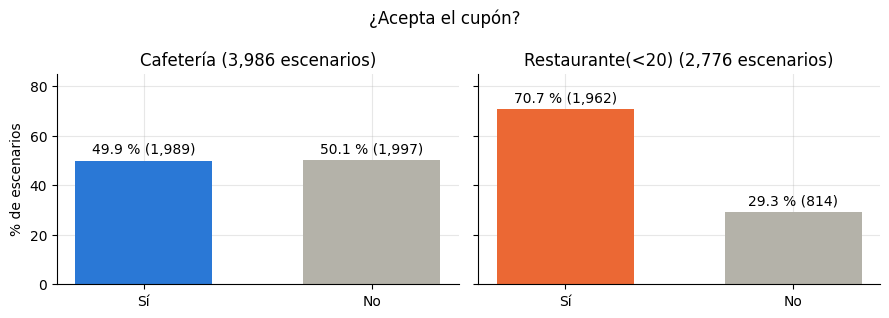

acepta_cupon,Sí,No,total,% Sí
Cafetería,1989,1997,3986,49.9
Restaurante(<20),1962,814,2776,70.7


In [8]:
subconjuntos = {c: datos[datos["cupon"] == c].copy() for c in CUPONES}
distribucion = pd.DataFrame({c: s["acepta_cupon"].value_counts() for c, s in subconjuntos.items()}).T[["Sí", "No"]]
distribucion["total"] = distribucion.sum(axis=1)
distribucion["% Sí"] = (100 * distribucion["Sí"] / distribucion["total"]).round(1)

fig, axes = plt.subplots(1, 2, figsize=(9, 3.2), sharey=True)
for ax, (cupon, fila) in zip(axes, distribucion.iterrows()):
    pct = 100 * fila[["Sí", "No"]] / fila["total"]
    barras = ax.bar(pct.index, pct.values, color=[COLOR[cupon], "#b4b2a9"], width=0.6)
    ax.bar_label(barras, labels=[f"{v:.1f} % ({int(n):,})" for v, n in zip(pct, fila[["Sí", "No"]])], padding=3)
    ax.set_title(f"{cupon} ({int(fila['total']):,} escenarios)")
    ax.set_ylim(0, 85)
axes[0].set_ylabel("% de escenarios")
fig.suptitle("¿Acepta el cupón?")
plt.tight_layout()
plt.show()
distribucion

El subconjunto de Cafetería (3.986 escenarios) está balanceado, con 49,9 % de aceptaciones y 50,1 % de rechazos. En
cambio, el de Restaurante(<20) (2.776 escenarios) está desbalanceado: el 70,7 % de los conductores acepta el cupón y
solo el 29,3 % lo rechaza, de modo que la clase minoritaria es No.

Este desbalance tiene dos consecuencias. La primera es que en Restaurante un modelo que siempre prediga Sí ya
alcanzaría una exactitud de 70,7 %, por lo que la accuracy no es una buena métrica y se deben revisar la precisión, el
recall y el F1-score de cada clase, en especial el recall de la clase No. La segunda es que la división en
entrenamiento y prueba y la validación cruzada deben ser estratificadas, para que ambas clases conserven su proporción
en cada partición.

### Visualización de la aceptación según el contexto

Para tener una primera idea de qué variables podrían ser informativas, se compara la proporción de aceptación según
los valores de algunas variables del contexto y del hábito de consumo del conductor.

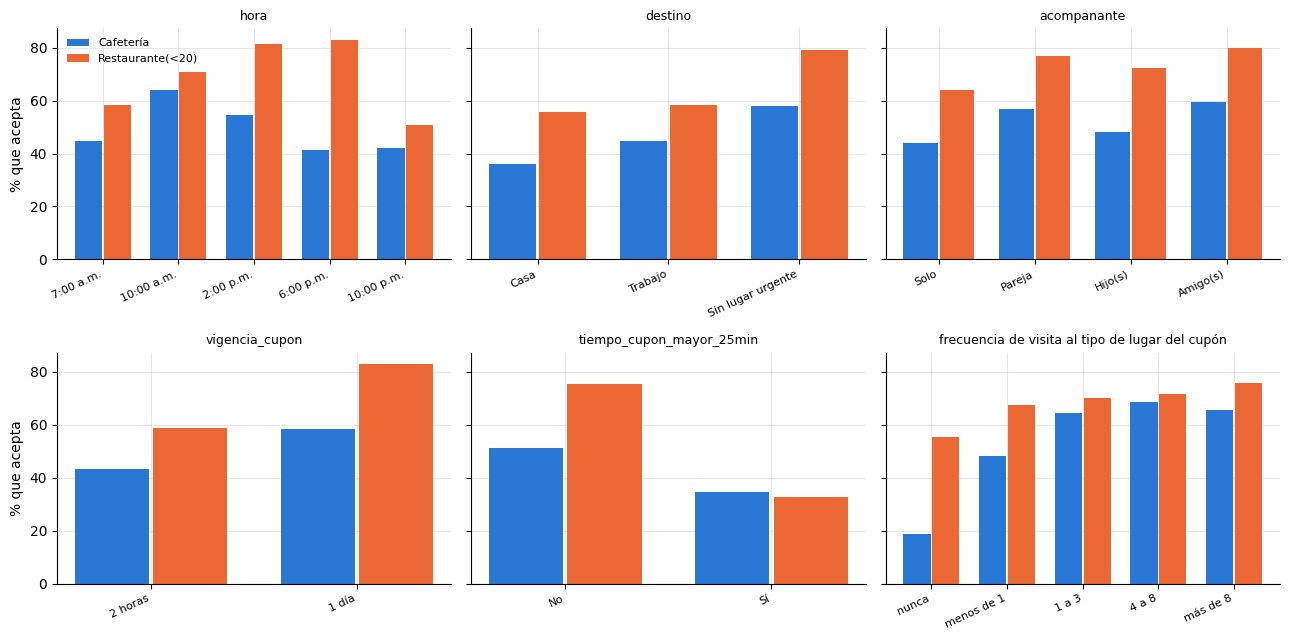

In [9]:
ORDEN_HORA = ["7:00 a.m.", "10:00 a.m.", "2:00 p.m.", "6:00 p.m.", "10:00 p.m."]
ORDEN_FRECUENCIA = ["nunca", "menos de 1", "1 a 3", "4 a 8", "más de 8"]
GRAFICOS = [
    ("hora", ORDEN_HORA),
    ("destino", ["Casa", "Trabajo", "Sin lugar urgente"]),
    ("acompanante", ["Solo", "Pareja", "Hijo(s)", "Amigo(s)"]),
    ("vigencia_cupon", ["2 horas", "1 día"]),
    ("tiempo_cupon_mayor_25min", ["No", "Sí"]),
    ("frecuencia propia", ORDEN_FRECUENCIA),
]
FRECUENCIA_PROPIA = {"Cafetería": "frecuencia_cafeteria", "Restaurante(<20)": "frecuencia_restaurante_menos_20"}

fig, axes = plt.subplots(2, 3, figsize=(13, 6.5), sharey=True)
for ax, (variable, orden) in zip(axes.flat, GRAFICOS):
    x = np.arange(len(orden))
    for k, (cupon, sub) in enumerate(subconjuntos.items()):
        col = FRECUENCIA_PROPIA[cupon] if variable == "frecuencia propia" else variable
        tasa = sub.groupby(col)["acepta_cupon"].apply(lambda s: (s == "Sí").mean()).reindex(orden)
        ax.bar(x + (k - 0.5) * 0.38, 100 * tasa.values, width=0.36, color=COLOR[cupon], label=cupon)
    ax.set_xticks(x, orden, rotation=25, ha="right", fontsize=8)
    ax.set_title(variable if variable != "frecuencia propia" else "frecuencia de visita al tipo de lugar del cupón",
                 fontsize=9)
for ax in axes[:, 0]:
    ax.set_ylabel("% que acepta")
axes[0, 0].legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

La variable que muestra la mayor diferencia es el hábito de consumo: en Cafetería, los conductores que nunca van a una
cafetería aceptan el cupón solo el 19 % de las veces, frente a un 65 %–69 % de quienes van al menos una vez al mes.
En Restaurante este efecto también existe, aunque es menor. La distancia también influye de forma clara, ya que cuando
el establecimiento está a más de 25 minutos la aceptación baja de 51 % a 35 % en Cafetería y de 75 % a 33 % en
Restaurante. Además, los cupones con vigencia de un día se aceptan más que los de dos horas, y la aceptación es mayor
cuando el conductor no tiene un lugar urgente al que llegar. En cuanto a la hora, Cafetería se acepta más a las
10:00 a.m. y Restaurante a las 2:00 p.m. y 6:00 p.m., lo que es coherente con los horarios de cada tipo de lugar. Por
el contrario, las variables demográficas como el género muestran diferencias mucho menores (49 % frente a 51 % en
Cafetería), lo cual será relevante para el análisis de sesgo.

### Datos de prueba

In [10]:
print("Cupones:", prueba["cupon"].value_counts().to_dict())
print("Mismas columnas que los datos (sin acepta_cupon):",
      list(prueba.columns) == [c for c in datos.columns if c != "acepta_cupon"])
print("Faltantes:", prueba.isna().sum().loc[lambda s: s > 0].to_dict())
nuevos = {c: set(prueba[c].dropna()) - set(datos[c].dropna()) for c in prueba.columns}
print("Valores que no aparecen en los datos de entrenamiento:", {c: v for c, v in nuevos.items() if v} or "ninguno")

Cupones: {'Cafetería': 10, 'Restaurante(<20)': 10}
Mismas columnas que los datos (sin acepta_cupon): True
Faltantes: {'vehiculo': 20}
Valores que no aparecen en los datos de entrenamiento: ninguno


Los datos de prueba tienen 10 escenarios de cada cupón, las mismas columnas que el conjunto de entrenamiento, ningún
valor que no aparezca en él y faltantes únicamente en `vehiculo`. Por lo tanto, la preparación que se defina a
continuación se les puede aplicar sin cambios.

### Conclusión exploración

En resumen, la exploración encontró problemas en las cuatro dimensiones de calidad. En completitud, la columna
`vehiculo` está casi vacía y las variables de frecuencia tienen un pequeño porcentaje de nulos. En unicidad, hay 7
filas duplicadas en cada subconjunto. En consistencia, se identificó una columna constante, una columna redundante y
algunos casos aislados de información contradictoria. En validez, los valores corresponden al diccionario, pero las
variables ordinales están guardadas como texto. Por último, el subconjunto de Restaurante(<20) presenta un desbalance
de clases (70,7 % / 29,3 %) que condiciona la elección de métricas y la forma de dividir los datos. Estos hallazgos
guían las decisiones de la siguiente etapa.

## Preparación de los datos

Las decisiones de preparación se dividen en dos grupos. Las que no aprenden nada de los datos (eliminar columnas y
duplicados) se aplican antes de dividir el conjunto. Las que sí aprenden de los datos, como la imputación y la
codificación, se incluyen dentro de un pipeline, de manera que en cada partición de la validación cruzada se ajusten
solo con los datos de entrenamiento y no haya fuga de información desde el conjunto de prueba.

### Eliminación de columnas y duplicados

In [11]:
COLUMNAS_ELIMINAR = ["vehiculo", "tiempo_cupon_mayor_5min", "direccion_opuesta", "cupon"]


def limpiar(df):
    """Elimina columnas sin información o redundantes. Se aplica igual a los datos y al archivo de prueba."""
    return df.drop(columns=COLUMNAS_ELIMINAR)


def preparar_subconjunto(cupon):
    """Filtra un tipo de cupón, limpia, quita duplicados exactos y separa X e y (1 = acepta)."""
    sub = limpiar(datos[datos["cupon"] == cupon]).drop_duplicates()
    return sub.drop(columns="acepta_cupon"), (sub["acepta_cupon"] == "Sí").astype(int)


for cupon in CUPONES:
    X, y = preparar_subconjunto(cupon)
    print(f"{cupon}: {X.shape[0]:,} escenarios × {X.shape[1]} variables | % acepta = {100 * y.mean():.1f}")

Cafetería: 3,979 escenarios × 21 variables | % acepta = 49.8
Restaurante(<20): 2,769 escenarios × 21 variables | % acepta = 70.7


Se eliminan cuatro columnas. La columna `vehiculo` se descarta porque tiene más del 99 % de valores nulos, y
`tiempo_cupon_mayor_5min` porque es constante. La columna `direccion_opuesta` se elimina por ser redundante con
`misma_direccion`, y `cupon` porque, una vez separado cada subconjunto, toma un solo valor. Después se eliminan los
duplicados exactos, conservando las filas con las mismas variables y distinta etiqueta por las razones expuestas en la
exploración. La variable objetivo se codifica como 1 cuando el conductor acepta el cupón y 0 cuando lo rechaza. Tras
este paso quedan 3.979 escenarios en Cafetería y 2.769 en Restaurante, con 21 variables de entrada cada uno.

### Tratamiento de nulos y codificación de variables

Cada tipo de variable recibe un tratamiento distinto mediante un `ColumnTransformer`, siguiendo el orden de categorías
indicado en el diccionario de datos.

In [12]:
ORDINALES = {
    "hora": ORDEN_HORA,
    "edad": ["menor de 21", "21", "26", "31", "36", "41", "46", "50 o más"],
    "educacion": ["Bachillerato incompleto", "Bachillerato completo", "Estudios universitarios sin título",
                  "Técnico/Tecnólogo", "Pregrado", "Posgrado (Maestría o Doctorado)"],
    "ingreso": ["Menos de $12.500", "$12.500 - $24.999", "$25.000 - $37.499", "$37.500 - $49.999",
                "$50.000 - $62.499", "$62.500 - $74.999", "$75.000 - $87.499", "$87.500 - $99.999",
                "$100.000 o más"],
    **{f: ORDEN_FRECUENCIA for f in ["frecuencia_bar", "frecuencia_cafeteria", "frecuencia_comida_para_llevar",
                                     "frecuencia_restaurante_menos_20", "frecuencia_restaurante_20_a_50"]},
    "vigencia_cupon": ["2 horas", "1 día"],
    **{b: ["No", "Sí"] for b in ["tiene_hijos", "tiempo_cupon_mayor_15min", "tiempo_cupon_mayor_25min",
                                 "misma_direccion"]},
}
NOMINALES = ["destino", "acompanante", "clima", "genero", "estado_civil", "ocupacion"]
NUMERICAS = ["temperatura"]


def crear_preprocesador(escalar=False):
    """Imputación + codificación por tipo de columna. escalar=True agrega StandardScaler (regresión logística)."""
    ordinales = Pipeline([
        ("imputar", SimpleImputer(strategy="most_frequent")),
        ("codificar", OrdinalEncoder(categories=list(ORDINALES.values()),
                                     handle_unknown="use_encoded_value", unknown_value=-1)),
    ])
    nominales = Pipeline([
        ("imputar", SimpleImputer(strategy="most_frequent")),
        ("codificar", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])
    columnas = ColumnTransformer([
        ("ordinales", ordinales, list(ORDINALES)),
        ("nominales", nominales, NOMINALES),
        ("numericas", "passthrough", NUMERICAS),
    ], verbose_feature_names_out=False)
    pasos = [("columnas", columnas)] + ([("escalar", StandardScaler())] if escalar else [])
    return Pipeline(pasos)

Los valores nulos de las variables de frecuencia se completan con la moda. Se eligió la moda porque son variables
categóricas, en las que no tiene sentido usar la media, y porque los nulos representan menos del 2 % de cada columna.
Eliminar las filas con algún nulo, en cambio, implicaría perder cerca del 4,5 % de los escenarios. La moda se calcula
dentro del pipeline, solo con los datos de entrenamiento.

Las variables ordinales se codifican con `OrdinalEncoder` usando el orden del diccionario, de forma que, por ejemplo,
una frecuencia de "4 a 8" visitas quede por encima de "1 a 3". Las variables binarias Sí/No se codifican de la misma
manera como 0 y 1. Las variables nominales (destino, acompañante, clima, género, estado civil y ocupación) se
codifican con `OneHotEncoder`, ya que asignarles números inventaría un orden que no existe; se usa
`handle_unknown="ignore"` para que una categoría no vista en entrenamiento no genere un error. La temperatura se
mantiene como numérica.

Por último, el escalado con `StandardScaler` solo se aplica en los modelos de regresión logística, porque su
regularización penaliza los coeficientes y depende de la escala de las variables. Los árboles de decisión y Random
Forest dividen por umbrales y no se ven afectados por la escala. Las variables demográficas se conservan, ya que el
caso pide evaluar precisamente el riesgo de sesgo de usarlas.

### División en entrenamiento y prueba

In [13]:
particiones = {}
for cupon in CUPONES:
    X, y = preparar_subconjunto(cupon)
    particiones[cupon] = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)

pd.DataFrame([{"cupón": c, "entrenamiento": len(p[0]), "prueba": len(p[1]),
               "% acepta (entrenamiento)": round(100 * p[2].mean(), 1),
               "% acepta (prueba)": round(100 * p[3].mean(), 1)} for c, p in particiones.items()])

,cupón,entrenamiento,prueba,% acepta (entrenamiento),% acepta (prueba)
0,Cafetería,3183,796,49.8,49.9
1,Restaurante(<20),2215,554,70.7,70.8


Cada subconjunto se divide en 80 % para entrenamiento y 20 % para prueba, con semilla 42. La división es
estratificada, por lo que la proporción de aceptación se mantiene prácticamente igual en ambas partes (49,8 % y
49,9 % en Cafetería; 70,7 % y 70,8 % en Restaurante). La búsqueda de hiperparámetros de las siguientes actividades se
hará con validación cruzada sobre el conjunto de entrenamiento, y el conjunto de prueba se reservará para la
comparación final de los modelos.

### Verificación del preprocesamiento

In [14]:
X_tr, X_te, y_tr, y_te = particiones["Restaurante(<20)"]
pre = crear_preprocesador().fit(X_tr)
M_tr, M_te = pre.transform(X_tr), pre.transform(X_te)
nombres = pre.get_feature_names_out()

assert not np.isnan(M_tr).any() and not np.isnan(M_te).any(), "quedaron valores faltantes"
assert M_tr.shape[1] == M_te.shape[1] == len(nombres)
print(f"{X_tr.shape[1]} variables originales -> {len(nombres)} columnas numéricas, sin faltantes")
pd.DataFrame(M_tr[:3], columns=nombres)

21 variables originales -> 57 columnas numéricas, sin faltantes


,hora,edad,educacion,ingreso,frecuencia_bar,frecuencia_cafeteria,frecuencia_comida_para_llevar,frecuencia_restaurante_menos_20,frecuencia_restaurante_20_a_50,vigencia_cupon,tiene_hijos,tiempo_cupon_mayor_15min,tiempo_cupon_mayor_25min,misma_direccion,destino_Casa,destino_Sin lugar urgente,destino_Trabajo,acompanante_Amigo(s),acompanante_Hijo(s),acompanante_Pareja,...,ocupacion_Computación y Matemáticas,ocupacion_Construcción y Extracción,ocupacion_Cuidado Personal y Servicios,ocupacion_Desempleado(a),"ocupacion_Educación, Formación y Bibliotecología",ocupacion_Estudiante,ocupacion_Gerencia,"ocupacion_Instalación, Mantenimiento y Reparación",ocupacion_Jubilado(a),ocupacion_Limpieza y Mantenimiento de Edificios,ocupacion_Negocios y Finanzas,ocupacion_Preparación y Servicio de Alimentos,ocupacion_Producción,ocupacion_Profesionales y Técnicos de la Salud,ocupacion_Servicios Comunitarios y Sociales,ocupacion_Servicios de Protección y Seguridad,ocupacion_Transporte y Manejo de Materiales,ocupacion_Ventas y afines,ocupacion_Área Legal,temperatura
0,4.0,4.0,4.0,8.0,1.0,0.0,2.0,1.0,1.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,30.0
1,2.0,5.0,5.0,4.0,0.0,2.0,2.0,2.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,80.0
2,0.0,7.0,1.0,1.0,0.0,0.0,3.0,2.0,1.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,30.0


Al ajustar el preprocesador con los datos de entrenamiento, las 21 variables de entrada se convierten en 57 columnas
numéricas: 14 de las variables ordinales y binarias, 42 de la codificación one-hot de las variables nominales (la
mayoría de ellas de `ocupacion`) y la temperatura. No quedan valores nulos, y los conjuntos de entrenamiento y prueba
tienen las mismas columnas. Este preprocesador será el primer paso de los pipelines de las actividades 3 a 5, con
escalado en el caso de la regresión logística.